In [1]:
import pandas as pd
import torch
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import cohen_kappa_score
import warnings
warnings.filterwarnings("ignore")

CRITERIA = ["c1", "c2", "c3", "c4", "c5"]
VALID_SCORES = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
RANDOM_SEED = 42

In [2]:
import random
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

## Load Data

In [3]:
train = pd.read_csv("/kaggle/input/competitions/enem-scoring/kaggle_output/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/enem-scoring/kaggle_output/test.csv")

print(f"Train: {train.shape}  |  Test: {test.shape}")
train.head(3)

Train: (3891, 9)  |  Test: (2594, 4)


,ID,prompt_title,prompt_category,essay,c1,c2,c3,c4,c5
0,3096,"Disciplina, ordem e autoridade favorecem a edu...",educação,Colégios militares têm ganhado muitos destaque...,0.8,1.0,0.6,0.6,0.0
1,5456,Parto humanizado: uma questão de saúde pública,saúde,"Na obra ""Utopia"", do escritor inglês Thomas Mo...",1.0,1.0,0.8,1.0,0.8
2,3481,SUS: desafios e importância da saúde pública n...,saúde,A série ''Sob pressão'' trata de uma realidade...,0.8,0.8,0.6,0.6,0.8


In [4]:
import re

def clean_text(t: str) -> str:
    t = str(t)

    # lowercase (nếu dùng cased model thì có thể bỏ dòng này)
    t = t.lower()

    # bỏ newline thừa
    t = re.sub(r"\n+", " ", t)

    # bỏ tab
    t = re.sub(r"\t+", " ", t)

    # bỏ ký tự lạ nhưng giữ dấu câu quan trọng
    t = re.sub(r"[^a-zà-ÿ0-9 .,;:!?()\[\]-]", " ", t)

    # gộp space
    t = re.sub(r"\s+", " ", t).strip()

    return t

In [5]:
train["prompt_title"] = train["prompt_title"].fillna("").apply(clean_text)
train["essay"] = train["essay"].fillna("").apply(clean_text)

In [6]:
print(train["essay"].iloc[0])

colégios militares têm ganhado muitos destaques por seu bom desempenho no enem e na disciplina dos seus alunos, porém existem muitos questionamentos sobre a rigidez impostas e quais são os impactos no aprendizado, na construção da identidade e dos valores de cada educando. a imposição no aprendizado através do autoritarismo foge dos padrões pedagógicos, os alunos aprendem pelo método da rigidez e do medo, parecem verdadeiros robôs que executam as tarefas pré-estabelecidas pela instituição, onde o senso crítico e o incentivo a criatividade praticamente não têm espaço. assim como argumenta a professora pilar lacerda na frase a escola de educação básica é o lugar da formação de valores, de conhecer e respeitar o outro. do diálogo e da construção de normas comuns. que cidadão está sendo formado neste modelo militar? a não ser que o jovem queira seguir carreira militar .a escola não pode ser um lugar burocrático é local para discussões e aprendizado, os alunos precisam se expressar e saber 

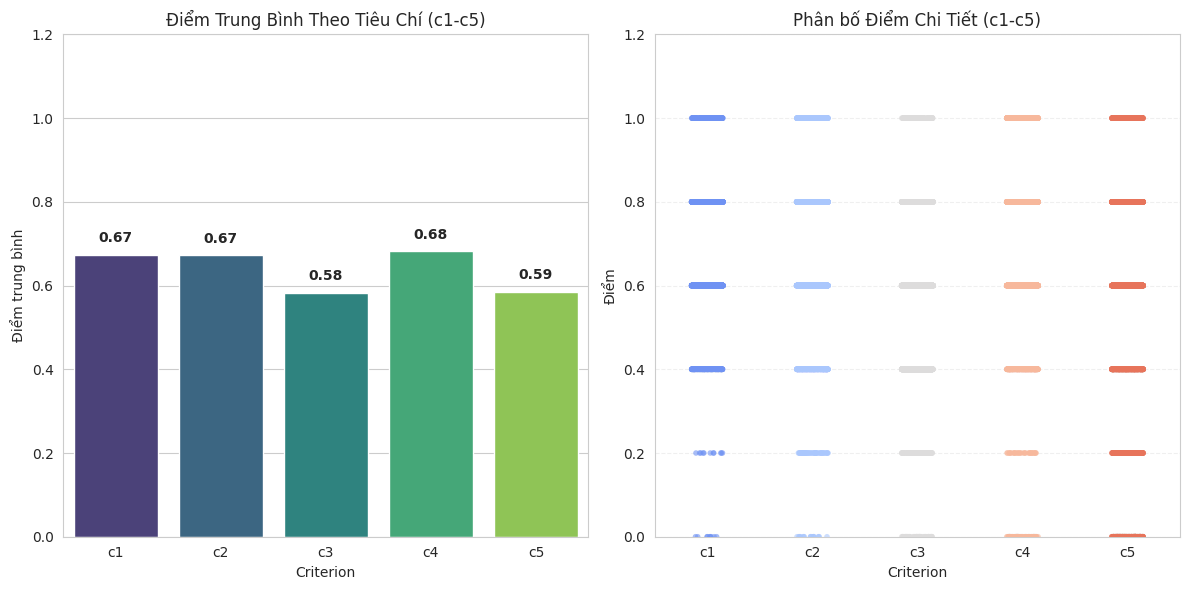

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=train
# 1. Chuẩn bị dữ liệu: Chọn các cột điểm
score_cols = ['c1', 'c2', 'c3', 'c4', 'c5']
df_scores = df[score_cols].melt(var_name='Criterion', value_name='Score')

sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))

# 3. Vẽ biểu đồ: Điểm trung bình theo từng tiêu chí (Bar plot)
plt.subplot(1, 2, 1)
avg_scores = df_scores.groupby('Criterion')['Score'].mean()
sns.barplot(x=avg_scores.index, y=avg_scores.values, palette='viridis')
plt.title('Điểm Trung Bình Theo Tiêu Chí (c1-c5)')
plt.ylabel('Điểm trung bình')
plt.ylim(0, 1.2)
for i, v in enumerate(avg_scores.values):
    plt.text(i, v + 0.03, f'{v:.2f}', ha='center', fontweight='bold')

# 4. Vẽ biểu đồ: Phân bố điểm (Scatter plot với jitter)
plt.subplot(1, 2, 2)
# Thêm nhiễu ngẫu nhiên nhẹ để các điểm không chồng lên nhau hoàn toàn
sns.stripplot(x='Criterion', y='Score', data=df_scores, 
              size=4, alpha=0.6, jitter=0.15, palette='coolwarm')
plt.title('Phân bố Điểm Chi Tiết (c1-c5)')
plt.ylabel('Điểm')
plt.ylim(0, 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

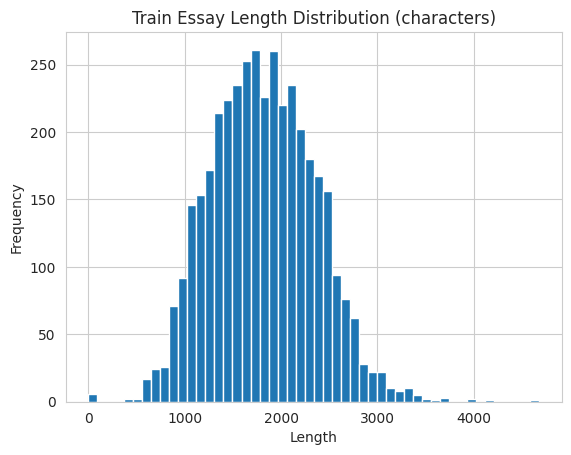

In [8]:
import matplotlib.pyplot as plt

# độ dài theo ký tự
lengths = train["essay"].fillna("").apply(len)

plt.figure()
plt.hist(lengths, bins=50)
plt.title("Train Essay Length Distribution (characters)")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.show()

## Feature Engineering

We build a single text feature by prepending the **prompt title** to the **essay body**.
This gives the model context about the expected topic, which is a key signal for ENEM graders.

In [9]:
def build_text(df: pd.DataFrame) -> pd.Series:
    """Concatenate prompt title and essay body into a single string."""
    prompt = df["prompt_title"].fillna("").str.strip()
    essay  = df["essay"].fillna("").str.strip()
    return "[TEMA] " + prompt + " [REDAÇÃO] " + essay

train["text"] = build_text(train)
test["text"]  = build_text(test)

print("Sample text (first 300 chars):")
print(train["text"].iloc[0][:300])

Sample text (first 300 chars):
[TEMA] disciplina, ordem e autoridade favorecem a educação? [REDAÇÃO] colégios militares têm ganhado muitos destaques por seu bom desempenho no enem e na disciplina dos seus alunos, porém existem muitos questionamentos sobre a rigidez impostas e quais são os impactos no aprendizado, na construção da


In [10]:
def normalize_scores(df: pd.DataFrame) -> pd.DataFrame:
    score_cols = [f'c{i}' for i in range(1, 6)]
    valid_scores = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    
    for col in score_cols:
        if col in df.columns:
            df[col] = df[col].apply(lambda x: x if x in valid_scores else float('nan'))
            df[col] = pd.to_numeric(df[col], errors='coerce')
            
    return df

In [11]:
print(df.head())

     ID                                       prompt_title  \
0  3096  disciplina, ordem e autoridade favorecem a edu...   
1  5456     parto humanizado: uma questão de saúde pública   
2  3481  sus: desafios e importância da saúde pública n...   
3   707  quais as soluções para os impactos ambientais ...   
4  5764  bicicletas e ciclofaixas esto chegando para fi...   

       prompt_category                                              essay  \
0             educação  colégios militares têm ganhado muitos destaque...   
1                saúde  na obra utopia , do escritor inglês thomas mor...   
2                saúde  a série sob pressão trata de uma realidade viv...   
3        meio ambiente  pode ser afirmar que os impactos ambientais ve...   
4  sociedade e cultura  um dos temas mais discutido hoje no brasil é a...   

    c1   c2   c3   c4   c5                                               text  
0  0.8  1.0  0.6  0.6  0.0  [TEMA] disciplina, ordem e autoridade favorece...  
1  1

In [12]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split

import torch
from torch.utils.data import Dataset

class EssayDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=512):

        self.texts = texts.reset_index(drop=True)
        self.labels = labels.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        text = str(self.texts.iloc[idx])

        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        label = self.labels.iloc[idx].values
        label = (label * 5).round().astype("int64")

        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)  # (5,)
        }

In [13]:
def collate_fn(batch):
    input_ids = [item["input_ids"] for item in batch]
    attention_mask = [item["attention_mask"] for item in batch]
    labels = torch.stack([item["labels"] for item in batch])
    batch_inputs = tokenizer.pad(
        {"input_ids": input_ids, "attention_mask": attention_mask},
        padding=True,
        return_tensors="pt"
    )
    batch_inputs["labels"] = labels
    return batch_inputs

In [14]:
from transformers import BertTokenizer
model_name = "neuralmind/bert-base-portuguese-cased"

tokenizer = BertTokenizer.from_pretrained(model_name)

train_dataset_full = EssayDataset(
    texts=train["text"],
    labels=train[["c1", "c2", "c3", "c4", "c5"]],
    tokenizer=tokenizer,
    max_length=512
)

train_size = int(0.8 * len(train_dataset_full))

valid_size = len(train_dataset_full) - train_size

train_dataset, valid_dataset = random_split(
    train_dataset_full,
    [train_size, valid_size]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    collate_fn=collate_fn
)

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [16]:
import torch
import torch.nn as nn
from transformers import BertModel

class ENEMModel(nn.Module):
    def __init__(self, model_name, dropout=0.2):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)
        hidden = self.bert.config.hidden_size

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, 5 * 6)

    def forward(self, input_ids, attention_mask):
        x = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).pooler_output

        x = self.dropout(x)
        x = self.classifier(x)

        return x.view(-1, 5, 6)

model = ENEMModel(model_name)
model.to(device)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ENEMModel(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(29794, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=

In [17]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from tqdm import tqdm

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=0.01
)

num_epochs = 9
num_training_steps = len(train_loader) * num_epochs

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * num_training_steps),
    num_training_steps=num_training_steps
)

def evaluate(model, data_loader, device):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            labels = batch["labels"].long().to(device)  # (B,5)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs  # (B,5,6)

            loss = criterion(
                logits.view(-1, 6),
                labels.view(-1)
            )

            total_loss += loss.item()

    return total_loss / len(data_loader)


best_val = 1e9

for epoch in range(num_epochs):

    model.train()
    total_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

    for batch in loop:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].long().to(device)  # (B,5)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs  # (B,5,6)

        loss = criterion(
            logits.view(-1, 6),
            labels.view(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        loop.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

    train_loss = total_loss / len(train_loader)
    val_loss = evaluate(model, val_loader, device)

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best.pt")
        print("Saved best model")

Epoch 1/9: 100%|██████████| 98/98 [05:09<00:00,  3.16s/it, loss=1.3679, lr=1.97e-04]


Epoch 1 | Train Loss: 1.4374 | Val Loss: 1.2688
Saved best model


Epoch 2/9: 100%|██████████| 98/98 [05:20<00:00,  3.27s/it, loss=1.2773, lr=1.73e-04]


Epoch 2 | Train Loss: 1.2237 | Val Loss: 1.2225
Saved best model


Epoch 3/9: 100%|██████████| 98/98 [05:20<00:00,  3.27s/it, loss=1.3700, lr=1.48e-04]


...

Epoch 7 | Train Loss: 0.8288 | Val Loss: 1.2776


Epoch 8/9: 100%|██████████| 98/98 [05:20<00:00,  3.27s/it, loss=0.6300, lr=2.47e-05]


Epoch 8 | Train Loss: 0.7667 | Val Loss: 1.2929


Epoch 9/9: 100%|██████████| 98/98 [05:20<00:00,  3.27s/it, loss=0.6260, lr=0.00e+00]


Epoch 9 | Train Loss: 0.7149 | Val Loss: 1.3047


In [18]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

test_df = pd.read_csv("/kaggle/input/competitions/enem-scoring/kaggle_output/test.csv")


def build_text(df):
    prompt = df["prompt_title"].fillna("").astype(str).str.strip()
    essay = df["essay"].fillna("").astype(str).str.strip()
    return "[TEMA] " + prompt + " [REDAÇÃO] " + essay

test_df["text"] = build_text(test_df)

# ======================
# Detect ID column
# ======================
id_col = "id" if "id" in test_df.columns else "ID"

# ======================
# Dataset
# ======================
class TestDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.texts = df["text"].tolist()
        self.ids = df[id_col].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "id": self.ids[idx],
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0)
        }

test_ds = TestDataset(test_df, tokenizer, max_len=512)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)


valid_labels = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], dtype=np.float32)
levels_t = torch.tensor(valid_labels, dtype=torch.float32, device=device)

model.load_state_dict(torch.load("best.pt", map_location=device))
model.to(device)
model.eval()

all_ids = []
all_preds = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Infer Test"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs  
        probs = torch.softmax(logits, dim=-1)

        scores = (probs * levels_t).sum(dim=-1)

        scores = scores.cpu().numpy()

        final_batch = []
        for row in scores:
            row_out = []
            for s in row:
                x = valid_labels[np.argmin(np.abs(valid_labels - s))]
                row_out.append(float(x))
            final_batch.append(row_out)

        all_preds.extend(final_batch)

        ids = batch["id"]
        if torch.is_tensor(ids):
            all_ids.extend(ids.cpu().tolist())
        else:
            all_ids.extend(list(ids))

sub = pd.DataFrame(all_preds, columns=["c1", "c2", "c3", "c4", "c5"])
sub.insert(0, "ID", all_ids)

sub.to_csv("submission.csv", index=False)

print(sub.head())
print("Saved submission.csv")

Infer Test: 100%|██████████| 163/163 [01:28<00:00,  1.85it/s]

     ID   c1   c2   c3   c4   c5
0  1327  0.6  0.6  0.6  0.6  0.4
1  6293  0.6  0.6  0.4  0.4  0.4
2   476  0.6  0.4  0.4  0.4  0.2
3  2811  0.8  0.8  0.6  0.8  0.6
4  4852  0.8  0.8  0.8  1.0  0.8
Saved submission.csv
